# Belt Conveyor Speed Control under Payload Change: Tuning, Scheduling and Windup

`11_conveyor_speed` | level 3 | experiment id(s): `exp_11_conveyor_speed`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 4 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Write a single-mass model of a belt conveyor with a lagged drive force, and verify it against the exact
  transfer function, the closed-form steady speed and momentum conservation.
- Identify a first-order-plus-dead-time (FOPDT) model from a step test at the operating point and check it
  against an independent property of the true plant.
- Tune a PI speed loop with the SIMC rule and predict, from the closed-loop poles, what happens when the
  payload changes the plant time constant.
- Compare a fixed PI, a PI scheduled on a known payload and a PI with static feed-forward for startup, a
  small step and an item dropped on a moving belt.
- Show why a reference the drive cannot reach winds up the integrator, and what anti-windup changes.
- Relate encoder resolution to the command ripple of a PI loop.

## 2. Real-World Engineering Problem

A conveyor that carries items of varying mass is asked to hold a belt speed (here 0.5 m/s) so that
downstream processes get a steady feed. Three things make this harder than a textbook first-order loop:
the plant time constant grows with the payload, an item landing on a moving belt removes speed
instantly (momentum), and the drive has a force limit, so a large demand cannot be met at once.
The questions answered with simulation: how bad is a PI tuned for one payload when the payload
changes, how much does scheduling on a known payload recover, and what limits the recovery.

## 3. Research Background

The identification and tuning method is the one used in notebooks 02 and 04: FOPDT fit from a step
response and the SIMC rules (Skogestad, 2003; Seborg et al., 2016). Anti-windup follows Astrom and
Hagglund (1995). Belt conveyors have their own standard for the calculation of driving force and
power (ISO 5048); it is cited as context only. No conveyor-control paper was searched or
verified in this build, so no conveyor-specific control result is cited.

## 4. Research Literature

The two books and the paper are cited for method. ISO 5048:1989 defines how resistances to motion and
driving force are calculated for a real conveyor; the full text is a paid document and was not read, so the
lumped parameters here (`c`, `mu`, `m_belt`) are **not** claimed to follow its definitions. All
parameters are illustrative, not from a product.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| skogestad2003 | Skogestad, S. (2003). Simple analytic rules for model reduction and PID controller tuning. Journal of Process Control, 13(4), 291-309. doi:10.1016/S0959-1524(02)00062-8. | SIMC rules and the half rule for effective delay. | An erratum exists (J. Process Control 14, 2004, p. 465). | verified (2026-11-25, web search of publisher/index/library record). Author-hosted record and an index record agree; the erratum was seen. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |
| iso5048 | ISO ISO 5048:1989, Continuous mechanical handling equipment - Belt conveyors with carrying idlers - Calculation of operating power and tensile forces (edition 2, 1989-09) | Scope: resistances to motion, driving force and power on the driving pulley. Context for the lumped resistance terms of the conveyor model; none of its formulas or coefficients is used. | ISO's page lists the edition as current; the English page says it was last reviewed and confirmed in 2019, the Spanish page says 2026 (unreconciled). | verified (2026-11-25, web search of publisher/index/library record). ISO catalogue record and abstract; the full text is paid and was not read. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Lumped model with equivalent mass $m=m_b+m_p$ (belt, rollers and reflected motor inertia plus payload),
belt speed $v$, drive force $F$ and normalised command $u\in[0,1]$:
$$\tau_t\dot F=F_{max}u-F,\qquad m\dot v=F-cv-\mu mg\tanh(v/\varepsilon)-d.$$
**Linearisation** ($\mu=0$): with $\tau_m=m/c$ and $K=F_{max}/c$,
$$G(s)=\frac{V(s)}{U(s)}=\frac{K}{(\tau_ts+1)(\tau_ms+1)}.$$
**Steady speed** for constant $u$ (with $v\gg\varepsilon$): $v_{ss}=(F_{max}u-\mu mg)/c$, so the **largest reachable
speed** is $v_{max}=(F_{max}-\mu mg)/c$, which falls as payload rises.
**Item landing.** A mass $\Delta m$ at rest captured instantly by the belt conserves momentum of the
equivalent mass: $v^+=\dfrac{m}{m+\Delta m}v^-$.

**FOPDT approximation.** The half rule (Skogestad, 2003) gives $T\approx\tau_m+\tau_t/2$, $L\approx\tau_t/2$;
the sum $T+L$ equals $\tau_m+\tau_t$. **SIMC PI:** $k_p=T/(K(\tau_c+L))$, $T_i=\min(T,4(\tau_c+L))$.
If $T_i=T$ the PI zero cancels the plant pole and the loop becomes $1/((\tau_c+L)s)$, independent of $T$.

**Closed-loop prediction** for a PI tuned on $T_0$ and applied to a plant with time constant $T$ (lag
ignored): characteristic polynomial $T_it\,T\,s^2+T_i(1+k_pK)s+k_pK$ with $t=1$; its damping ratio gives the
overshoot, and I compute it from the full transfer function with `scipy` instead of the approximation.

**Force-limited acceleration.** With $u=1$ held, $v(t)=v_{max}(1-e^{-t/\tau_m})$ (drive lag neglected), so the
10 to 90 percent rise time to a target $v_r$ is
$\tau_m\ln\frac{1-0.1v_r/v_{max}}{1-0.9v_r/v_{max}}$.

## 6. System Modeling

Illustrative bench-scale parameters: `m_belt = 12 kg`, `c = 40 N s/m`, `mu = 0.03`, `F_max = 40 N`,
`tau_t = 50 ms`, `eps = 0.01 m/s`. So `K = 1.0 (m/s)/unit`, `tau_m = 0.30 s` empty and `1.05 s` with
30 kg, and `v_max = 0.912 m/s` empty and `0.691 m/s` with 30 kg. There is no stiction: friction is
a smoothed Coulomb term. Sample time 10 ms (RK4, 5 substeps); the drive command is held between samples.
Reference 0.5 m/s. Payloads 0, 10 and 30 kg. The viscous term `c` lumps belt, gearbox and motor
losses; a real conveyor may be nearer to an integrator with friction, and the design would change.
The speed sensor is a roller encoder of 0.08 m diameter measured over one 10 ms window.

## 7. Dataset and Measurement Data

No dataset; the conveyor is simulated and every number is a simulation result. The encoder is modelled
only as a speed quantisation step `pi D / (PPR Ts)` applied to the measurement.

## 8. Algorithm Architecture

Identification step test on the empty belt around the operating speed (0.4 to 0.5 m/s), least-squares
FOPDT fit, SIMC PI with `tau_c = 0.2 s`. Four controllers, all with output limits 0 to 1:
**A** fixed PI tuned on the empty belt; **B** fixed PI tuned on 30 kg; **C** PI whose `T` is scaled by
`(m_belt + m_p)/m_belt` from the known payload (a perfect load cell); **D** = C plus static
feed-forward of the steady command `(c v + mu m g)/F_max`, which uses the true model.

## 9. Algorithm Implementation

In [2]:
import pandas as pd
from scipy import signal
from control_lab.controllers import PID
from control_lab.controllers.tuning import simc_pi
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.identification import fit_fopdt_least_squares
from control_lab.metrics import iae, step_response_metrics
from control_lab.models import BeltConveyor, ConveyorParams
from control_lab.simulation import run_closed_loop

EXP = "exp_11_conveyor_speed"
P = ConveyorParams()
Ts, V_REF, TAU_C, M_FULL = 0.01, 0.5, 0.2, 30.0
PAYLOADS = [0.0, 10.0, 30.0]
ENC_DIAMETER = 0.08

def identify(p=P, v_lo=0.4, v_hi=0.5, settle=4.0, t_fit=4.0):
    belt = BeltConveyor(p, Ts=Ts)
    u_lo, u_hi = belt.command_for_speed(v_lo), belt.command_for_speed(v_hi)
    for _ in range(int(settle / Ts)): belt.step(u_lo)
    y0 = belt.y
    ys = [belt.step(u_hi) for _ in range(int(t_fit / Ts))]
    t = np.arange(len(ys) + 1) * Ts
    y = np.r_[y0, ys] - y0
    fit = fit_fopdt_least_squares(t, y, u_hi - u_lo)
    return fit, t, y, u_hi - u_lo

ID, T_ID, Y_ID, DU_ID = identify()

def tune(mass_payload, tau_c=TAU_C):
    Tm = ID["T"] * (P.m_belt + mass_payload) / P.m_belt
    return simc_pi(ID["K"], Tm, ID["L"], tau_c=tau_c)

class PayloadPI:
    # PI with SIMC gains from a fixed or scheduled payload, optional static feed-forward
    def __init__(self, belt, mode, ff=False, aw="backcalc", tau_c=TAU_C):
        self.belt, self.mode, self.ff, self.tau_c = belt, mode, ff, tau_c
        self.pid = PID.from_times(1.0, 1.0, 0.0, Ts=Ts, u_min=0.0, u_max=1.0, antiwindup=aw)
        self._gains()
    def _gains(self):
        mp = {"empty": 0.0, "full": M_FULL}.get(self.mode, self.belt.m_payload)
        s = tune(mp, self.tau_c)
        self.pid.kp, self.pid.ki, self.pid.tt = s["kp"], s["kp"] / s["ti"], s["ti"]
        return s
    def reset(self):
        self.pid.reset(); self._gains()
    def update(self, r, y):
        self._gains()
        uff = self.belt.command_for_speed(r, self.belt.m_payload) if self.ff else 0.0
        return self.pid.update(r, y, uff)

KINDS = {"A fixed, tuned empty": dict(mode="empty"), "B fixed, tuned 30 kg": dict(mode="full"),
         "C scheduled on payload": dict(mode="sched"), "D scheduled + feed-forward": dict(mode="sched", ff=True)}

def run(kind, mp, ref, t_end, events=None, p=P, aw="backcalc", quant=0.0, tau_c=TAU_C):
    belt = BeltConveyor(p, Ts=Ts, m_payload=mp, payload_events=events)
    ctl = PayloadPI(belt, aw=aw, tau_c=tau_c, **KINDS[kind])
    n = int(round(t_end / Ts))
    r = ref(np.arange(n) * Ts) if callable(ref) else np.full(n, ref)
    o = run_closed_loop(belt, ctl, r, Ts, quant_step=quant)
    o["belt"] = belt
    return o

def recovery_time(t, y, ref, t0, band):
    k0 = int(round(t0 / Ts))
    out = np.flatnonzero(np.abs(y[k0:] - ref) > band)
    return float(out[-1] * Ts) if out.size else 0.0

The scheduled controller reads `belt.m_payload` directly, which is an ideal load cell. Gains are
recomputed every sample; the integrator stores `ki * integral(e)`, so a change of `ki` does not jump
the output, but a change of `kp` does jump the proportional term (small, since payload changes in steps).

## 10. Simulation and Numerical Analysis

Section 12 runs, in order: model verification, identification, linear closed-loop verification against
the exact transfer function, startup from rest, the small step at the operating point, the item
drop, the unreachable reference with three anti-windup settings, and the encoder study. Each result
that is compared with an independent calculation is a check; the rest are reported as measurements.

## 11. Experimental Validation

Level: **software simulation**. Independent references: `scipy.signal.step` on the exact transfer function,
the closed-form steady speed, momentum conservation, the exact eigenvalues of the state matrix, the
force-limited rise-time formula and the sum of time constants. Comparisons between controllers are
simulation results only; no belt, drive, encoder or load cell was used.

## 12. Performance Evaluation

In [3]:
checks = []
# --- model verification
p0 = P.with_changes(mu=0.0)
b = BeltConveyor(p0, Ts=0.005, m_payload=10.0); n = 400
y_sim = np.array([b.y] + [b.step(0.4) for _ in range(n - 1)]); tt = np.arange(n) * 0.005
num, den = b.linear_tf()
_, y_ex = signal.step(signal.TransferFunction(np.array(num) * 0.4, den), T=tt)
e = np.max(np.abs(y_sim - y_ex)) / y_ex[-1]
checks.append(check("open-loop step matches scipy exact step (max error / final)", e < 2e-3, f"{e:.2e}"))
m_ = p0.m_belt + 10.0
A = np.array([[-p0.c / m_, 1 / m_], [0.0, -1 / p0.tau_t]])
pa, pb = np.sort(np.linalg.eigvals(A).real), np.sort(np.roots(den).real)
checks.append(check("transfer-function poles equal state-matrix eigenvalues", np.allclose(pa, pb, rtol=1e-8), f"{pb}"))
for mp in PAYLOADS:
    b = BeltConveyor(P, Ts=Ts, m_payload=mp)
    for _ in range(int(40 / Ts)): b.step(0.7)
    ref_v = (P.F_max * 0.7 - P.mu * (P.m_belt + mp) * 9.80665) / P.c
    checks.append(check(f"steady speed at u=0.7 equals (F_max u - mu m g)/c, payload {mp:g} kg", abs(b.y - ref_v) / ref_v < 2e-3, f"{b.y:.4f} vs {ref_v:.4f} m/s"))

# --- identification
tm0 = P.m_belt / P.c
checks.append(check("identified K within 1% of F_max/c", abs(ID["K"] - P.F_max / P.c) / (P.F_max / P.c) < 0.01, f"{ID['K']:.4f} vs {P.F_max / P.c:.4f}"))
checks.append(check("identified T + L within 3% of tau_m + tau_t (sum of time constants)", abs(ID["T"] + ID["L"] - (tm0 + P.tau_t)) / (tm0 + P.tau_t) < 0.03, f"{ID['T'] + ID['L']:.4f} vs {tm0 + P.tau_t:.4f} s"))
half = dict(T=tm0 + P.tau_t / 2, L=P.tau_t / 2)
ident_vs_halfrule = dict(T_fit=ID["T"], L_fit=ID["L"], T_half=half["T"], L_half=half["L"], rmse=ID["rmse"])
print({k: round(v, 4) for k, v in ident_vs_halfrule.items()})

# --- linear closed loop against the exact transfer function (mu = 0, no limits)
def linear_error(mp, Ts_, t_end=6.0):
    s = tune(0.0)
    bl = BeltConveyor(p0, Ts=Ts_, m_payload=mp, substeps=max(2, int(Ts_ / 0.002)))
    cl = PID.from_times(s["kp"], s["ti"], 0.0, Ts=Ts_)
    nn = int(round(t_end / Ts_)); o = run_closed_loop(bl, cl, np.full(nn, V_REF), Ts_)
    nm, dn = bl.linear_tf(); kp, ti = s["kp"], s["ti"]
    ol_n = np.polymul([kp * ti, kp], nm); ol_d = np.polymul([ti, 0.0], dn)
    _, ye = signal.step(signal.TransferFunction(ol_n * V_REF, np.polyadd(ol_d, ol_n)), T=o["t"])
    return np.max(np.abs(o["y"] - ye)) / V_REF, o["y"].max() / V_REF - 1, ye.max() / V_REF - 1, np.roots(np.polyadd(ol_d, ol_n))
lin = {}
for mp in (0.0, 30.0):
    lin[mp] = {Ts_: linear_error(mp, Ts_) for Ts_ in (0.01, 0.005)}
    e10, os_s, os_r, poles = lin[mp][0.01]; e5 = lin[mp][0.005][0]
    checks.append(check(f"linear closed loop, payload {mp:g} kg: error vs exact < 2% of step at Ts = 10 ms", e10 < 0.02, f"{100 * e10:.2f} %"))
    checks.append(check(f"linear closed loop, payload {mp:g} kg: error halves when Ts halves (ratio 1.8 to 2.2)", 1.8 < e10 / e5 < 2.2, f"ratio {e10 / e5:.2f}"))
checks.append(check("empty-tuned PI on 30 kg: simulated overshoot equals exact-model overshoot within 1 point", abs(lin[30.0][0.01][1] - lin[30.0][0.01][2]) < 0.01, f"{100 * lin[30.0][0.01][1]:.1f} % vs {100 * lin[30.0][0.01][2]:.1f} %"))

# --- startup from rest, nonlinear plant with limits
rows_start, store_start = [], {}
for kind in list(KINDS)[:3] + [list(KINDS)[3]]:
    for mp in PAYLOADS:
        o = run(kind, mp, V_REF, 10.0); store_start[(kind, mp)] = o
        m = step_response_metrics(o["t"], o["y"], V_REF)
        rows_start.append(dict(controller=kind, payload_kg=mp, rise_10_90_s=m["rise_time_10_90"], overshoot_pct=m["overshoot_percent"],
                               settling_s=m["settling_time"], iae=iae(o["t"], o["e"]), peak_cmd=float(o["u"].max()),
                               sat_fraction_pct=100 * float(np.mean(o["u"] >= 1 - 1e-9)), ess_pct=100 * abs(V_REF - o["y"][-1]) / V_REF))
df_start = pd.DataFrame(rows_start)
print(df_start.round(3).to_string(index=False))
checks.append(check("zero steady-state error for every controller and payload (startup)", bool((df_start.ess_pct < 0.5).all()), f"max {df_start.ess_pct.max():.3f} %"))
vmax30 = BeltConveyor(P).max_speed(30.0)
rise_th = (P.m_belt + 30.0) / P.c * np.log((1 - 0.1 * V_REF / vmax30) / (1 - 0.9 * V_REF / vmax30))
rise_sim = df_start[(df_start.controller == "C scheduled on payload") & (df_start.payload_kg == 30.0)].rise_10_90_s.iloc[0]
checks.append(check("30 kg startup rise time equals the force-limited formula within 5%", abs(rise_sim - rise_th) / rise_th < 0.05, f"{rise_sim:.3f} s vs {rise_th:.3f} s"))

# --- small step at the operating point (linear regime), warm start
rows_small, store_small = [], {}
for kind in list(KINDS)[:3]:
    for mp in PAYLOADS:
        o = run(kind, mp, lambda t: np.where(t < 15.0, 0.45, 0.5), 25.0); store_small[(kind, mp)] = o
        i0 = int(15.0 / Ts)
        m = step_response_metrics(o["t"][i0:] - 15.0, o["y"][i0:], 0.5, y_initial=0.45)
        rows_small.append(dict(controller=kind, payload_kg=mp, rise_10_90_s=m["rise_time_10_90"], overshoot_pct=m["overshoot_percent"], settling_s=m["settling_time"]))
df_small = pd.DataFrame(rows_small)
print(df_small.round(3).to_string(index=False))
def spread(kind):
    r = df_small[df_small.controller == kind].rise_10_90_s
    return float(r.max() / r.min() - 1)
sp_fix, sp_sched = spread("A fixed, tuned empty"), spread("C scheduled on payload")
checks.append(check("scheduled PI: small-step rise time varies less than 10% across payloads", sp_sched < 0.10, f"{100 * sp_sched:.1f} %"))
checks.append(check("fixed PI: same spread is more than 3x the scheduled spread", sp_fix > 3 * sp_sched, f"{100 * sp_fix:.1f} % vs {100 * sp_sched:.1f} %"))

# --- item drop on a moving belt (settled before the event)
T_DROP, DM, MP0 = 6.0, 15.0, 5.0
rows_drop, store_drop = [], {}
for kind in KINDS:
    o = run(kind, MP0, V_REF, 14.0, events=[(T_DROP, DM)]); store_drop[kind] = o
    k = int(round(T_DROP / Ts)); y = o["y"]
    v_pre = y[k]; v_post_ref = v_pre * (P.m_belt + MP0) / (P.m_belt + MP0 + DM)
    rows_drop.append(dict(controller=kind, v_pre=v_pre, v_after_one_sample=y[k + 1], v_momentum=v_post_ref,
                          dip_m_s=V_REF - y[k:].min(), recovery_s=recovery_time(o["t"], y, V_REF, T_DROP, 0.025),
                          iae_after=iae(o["t"][k:], o["e"][k:]), peak_cmd=float(o["u"][k:].max()),
                          sat_fraction_pct=100 * float(np.mean(o["u"][k:] >= 1 - 1e-9))))
df_drop = pd.DataFrame(rows_drop)
print(df_drop.round(4).to_string(index=False))
dev = np.abs(df_drop.v_after_one_sample - df_drop.v_momentum) / df_drop.v_momentum
checks.append(check("speed one sample after the drop equals the momentum prediction within 1.5% (all controllers)", bool((dev < 0.015).all()), f"max {100 * dev.max():.2f} %"))
rec = df_drop.set_index("controller").recovery_s
checks.append(check("scheduled PI recovers from the drop at least 2x faster than the empty-tuned PI", rec["C scheduled on payload"] * 2 <= rec["A fixed, tuned empty"], f"{rec['C scheduled on payload']:.2f} s vs {rec['A fixed, tuned empty']:.2f} s"))

# --- reference above the reachable speed, three anti-windup settings
def ref_hi(t): return np.where(t < 6.0, 0.8, 0.4)
rows_aw, store_aw = [], {}
for aw in ("none", "clamp", "backcalc"):
    o = run("C scheduled on payload", 30.0, ref_hi, 16.0, aw=aw); store_aw[aw] = o
    k = int(6.0 / Ts)
    rows_aw.append(dict(antiwindup=aw, speed_before_drop=float(o["y"][k - 10]), recovery_s=recovery_time(o["t"], o["y"], 0.4, 6.0, 0.02),
                        min_speed_after=float(o["y"][k:].min()), iae_after=iae(o["t"][k:], o["e"][k:])))
df_aw = pd.DataFrame(rows_aw).set_index("antiwindup")
print(df_aw.round(4))
v_ceiling = BeltConveyor(P).max_speed(30.0)
checks.append(check("with back-calculation the speed saturates at the closed-form maximum within 1%", abs(df_aw.loc["backcalc", "speed_before_drop"] - v_ceiling) / v_ceiling < 0.01, f"{df_aw.loc['backcalc', 'speed_before_drop']:.4f} vs {v_ceiling:.4f} m/s"))
rc = df_aw.recovery_s
checks.append(check("recovery time order after the reference drops: none > clamp > back-calculation", bool(rc["none"] > rc["clamp"] > rc["backcalc"]), f"{rc['none']:.2f} > {rc['clamp']:.2f} > {rc['backcalc']:.2f} s"))

# --- encoder resolution
rows_enc, store_enc = [], {}
for ppr in (100, 400, 1600):
    q = np.pi * ENC_DIAMETER / ppr / Ts
    o = run("C scheduled on payload", 10.0, V_REF, 20.0, quant=q); store_enc[ppr] = o
    a = int(10.0 / Ts); kp_ = tune(10.0)["kp"]
    rows_enc.append(dict(ppr=ppr, quant_m_s=q, kp_times_q=kp_ * q, cmd_ptp=float(np.ptp(o["u"][a:])), speed_ptp_pct=100 * float(np.ptp(o["y"][a:])) / V_REF))
df_enc = pd.DataFrame(rows_enc)
print(df_enc.round(4).to_string(index=False))
ratio = df_enc.cmd_ptp / df_enc.kp_times_q
checks.append(check("command peak-to-peak ripple is 0.7 to 1.3 times kp * (one encoder step)", bool(((ratio > 0.7) & (ratio < 1.3)).all()), f"ratios {np.round(ratio.values, 2)}"))
checks.append(check("speed ripple falls monotonically with encoder resolution", bool(df_enc.speed_ptp_pct.is_monotonic_decreasing), f"{df_enc.speed_ptp_pct.round(3).tolist()} %"))

for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

{'T_fit': 0.3107, 'L_fit': 0.0428, 'T_half': 0.325, 'L_half': 0.025, 'rmse': 0.0004}


                controller  payload_kg  rise_10_90_s  overshoot_pct  settling_s   iae  peak_cmd  sat_fraction_pct  ess_pct
      A fixed, tuned empty         0.0         0.502          0.000        1.03 0.140     0.728               0.0    0.000
      A fixed, tuned empty        10.0         0.573          5.567        1.85 0.202     0.862               0.0    0.000
      A fixed, tuned empty        30.0         1.044          9.522        2.97 0.378     1.000              11.7    0.002
      B fixed, tuned 30 kg         0.0         0.252          0.000        2.52 0.157     1.000               1.9    0.003
      B fixed, tuned 30 kg        10.0         0.516          0.000        2.41 0.196     1.000               3.5    0.002
      B fixed, tuned 30 kg        30.0         1.041          0.000        1.93 0.315     1.000              10.6    0.000
    C scheduled on payload         0.0         0.502          0.000        1.03 0.140     0.728               0.0    0.000
    C scheduled 

            controller  payload_kg  rise_10_90_s  overshoot_pct  settling_s
  A fixed, tuned empty         0.0         0.413          0.000        0.80
  A fixed, tuned empty        10.0         0.481          7.957        1.80
  A fixed, tuned empty        30.0         0.624         20.091        3.75
  B fixed, tuned 30 kg         0.0         0.120          0.000        2.21
  B fixed, tuned 30 kg        10.0         0.212          0.000        1.78
  B fixed, tuned 30 kg        30.0         0.381          0.695        0.64
C scheduled on payload         0.0         0.413          0.000        0.80
C scheduled on payload        10.0         0.406          0.000        0.78
C scheduled on payload        30.0         0.381          0.695        0.64


                controller  v_pre  v_after_one_sample  v_momentum  dip_m_s  recovery_s  iae_after  peak_cmd  sat_fraction_pct
      A fixed, tuned empty 0.5000              0.2672      0.2656   0.2328        1.66     0.1156    0.9821              0.00
      B fixed, tuned 30 kg 0.4996              0.2669      0.2654   0.2331        0.48     0.0706    1.0000              5.00
    C scheduled on payload 0.5000              0.2672      0.2656   0.2328        0.49     0.0760    1.0000              4.50
D scheduled + feed-forward 0.5000              0.2672      0.2656   0.2328        0.48     0.0907    1.0000              5.25


            speed_before_drop  recovery_s  min_speed_after  iae_after
antiwindup                                                           
none                   0.6884        5.97           0.4003     1.2641
clamp                  0.6884        1.62           0.3601     0.1179
backcalc               0.6884        0.51           0.3976     0.0743


 ppr  quant_m_s  kp_times_q  cmd_ptp  speed_ptp_pct
 100     0.2513      0.5890   0.4680         1.2691
 400     0.0628      0.1473   0.1498         0.2561
1600     0.0157      0.0368   0.0385         0.1430
22 of 22 checks passed


The model checks (open loop, poles, steady speed) test the plant; the identification checks test the
fit against two independent properties of the true plant; the linear closed-loop checks test the
discretisation, including that the error is first order in the sample time, as expected for a
forward-Euler integrator with a held input. The remaining checks test predictions of the design
(force-limited rise time, momentum, scheduling spread, saturation ceiling). The tolerance for the
scheduling spread (10%) and for the encoder ripple ratio (0.7 to 1.3) were set after I had seen a
first run, so those two are consistency checks, not blind predictions.

## 13. Visualization and Interpretation

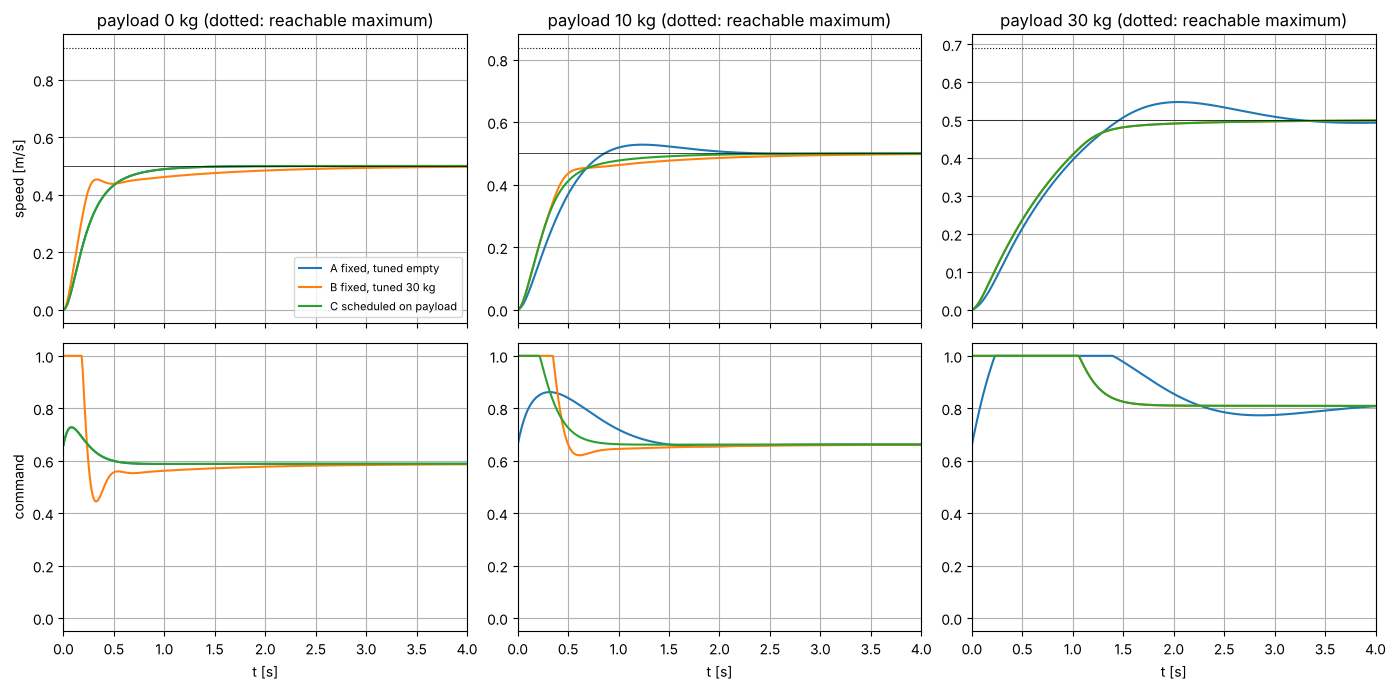

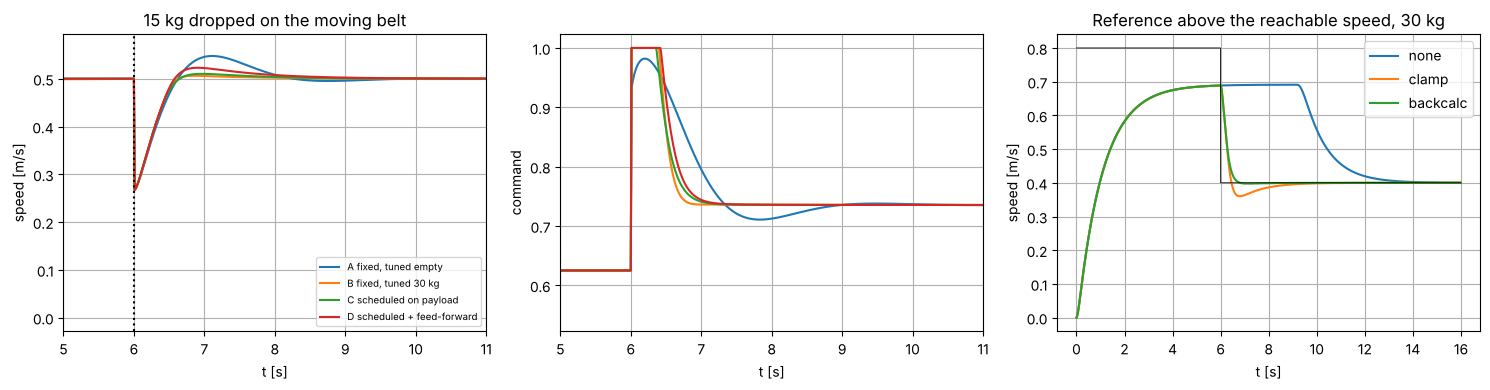

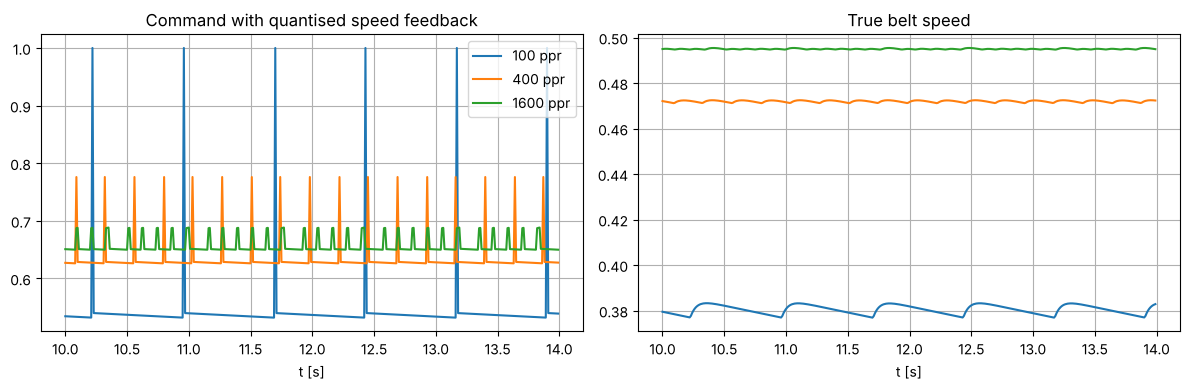

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7), sharex="col")
for j, mp in enumerate(PAYLOADS):
    for kind in list(KINDS)[:3]:
        o = store_start[(kind, mp)]
        ax[0, j].plot(o["t"], o["y"], label=kind); ax[1, j].plot(o["t"], o["u"])
    ax[0, j].axhline(V_REF, color="k", lw=0.5); ax[0, j].axhline(BeltConveyor(P).max_speed(mp), color="k", ls=":", lw=0.8)
    ax[0, j].set(title=f"payload {mp:g} kg (dotted: reachable maximum)", xlim=(0, 4)); ax[1, j].set(xlabel="t [s]", ylim=(-0.05, 1.05))
ax[0, 0].set(ylabel="speed [m/s]"); ax[1, 0].set(ylabel="command"); ax[0, 0].legend(fontsize=8)
fig.tight_layout(); figs = [save_figure(fig, EXP, "startup_by_payload")]; plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for kind in KINDS:
    o = store_drop[kind]; ax[0].plot(o["t"], o["y"], label=kind); ax[1].plot(o["t"], o["u"])
ax[0].axvline(T_DROP, color="k", ls=":"); ax[0].set(xlim=(5, 11), title="15 kg dropped on the moving belt", xlabel="t [s]", ylabel="speed [m/s]"); ax[0].legend(fontsize=7)
ax[1].set(xlim=(5, 11), xlabel="t [s]", ylabel="command")
for aw in ("none", "clamp", "backcalc"):
    o = store_aw[aw]; ax[2].plot(o["t"], o["y"], label=aw)
ax[2].plot(o["t"], o["r"], "k", lw=0.6); ax[2].set(title="Reference above the reachable speed, 30 kg", xlabel="t [s]", ylabel="speed [m/s]"); ax[2].legend()
fig.tight_layout(); figs.append(save_figure(fig, EXP, "item_drop_and_windup")); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for ppr, o in store_enc.items():
    a, b_ = int(10 / Ts), int(14 / Ts)
    ax[0].plot(o["t"][a:b_], o["u"][a:b_], label=f"{ppr} ppr"); ax[1].plot(o["t"][a:b_], o["y"][a:b_])
ax[0].set(title="Command with quantised speed feedback", xlabel="t [s]"); ax[0].legend(); ax[1].set(title="True belt speed", xlabel="t [s]")
fig.tight_layout(); figs.append(save_figure(fig, EXP, "encoder_resolution")); plt.show()

Figure 1 separates what tuning can change from what the drive limit sets: at 30 kg all controllers
share the same saturated rise. Figure 2 shows the drop (left, centre) and the unreachable reference (right).

## 14. Research Discussion and Limitations

**Facts from this run (tables in section 12).**
- **Model.** Open-loop error against the exact transfer function is 5e-11 of the final value; steady speeds match the closed
  form to four decimals at 0, 10 and 30 kg.
- **Identification.** `K = 1.0008` (true 1.0). The fit gives `T = 0.311 s`, `L = 0.043 s`; the half rule gives `T = 0.325 s`,
  `L = 0.025 s`. So `T` is 4% below and `L` 71% above the half-rule values, but the sum `T + L = 0.3535 s` is within 1.0% of
  `tau_m + tau_t = 0.350 s`. The step test recovers the sum of the lags, not the split between them.
- **Discretisation.** Against the exact continuous closed loop the maximum error is 1.33% (empty) and 0.77% (30 kg) of the
  step at Ts = 10 ms, and halves when Ts halves (ratios 2.01 and 2.00), i.e. first order in Ts.
- **Payload shifts the loop shape.** The PI tuned on the empty belt, applied at 30 kg, overshoots 20.1% in the linear
  model (exact reference 20.0%). In the small step at the operating point the rise time across 0, 10, 30 kg is
  0.413, 0.481, 0.624 s for the fixed PI (spread 51%) and 0.413, 0.406, 0.381 s for the scheduled PI (spread 8.4%); overshoot
  0, 8.0, 20.1% against 0, 0, 0.7%. The PI tuned on 30 kg applied to the empty belt rises in 0.12 s but takes 2.21 s to
  settle, a slow integrator tail.
- **The drive limit sets large-signal behaviour.** Startup at 30 kg takes 1.04 s to rise for all four controllers (1.03 to
  1.04 s), against 1.027 s from the force-limited formula. The same fixed PI that overshoots 20.1% in the linear model overshoots
  9.5% from rest, because the command is at its limit during 11.7% of the samples.
- **Item drop.** 15 kg on a belt at 0.5 m/s (5 kg payload) removes 0.233 m/s (47%) at once for every controller; the speed one
  sample later is within 0.58% of the momentum prediction. The dip is set by physics, not by the controller. Return to a
  +/-0.025 m/s band (5% of the reference) takes 1.66 s (A), 0.48 s (B), 0.49 s (C), 0.48 s (D); IAE after the drop 0.116, 0.071, 0.076, 0.091.
- **Static feed-forward (D).** Startup rise at 0 kg falls from 0.502 s to 0.214 s, but overshoot rises from 0% to 17.0%
  (10.1% at 10 kg, 4.4% at 30 kg), and the drop IAE is 20% higher than C (0.091 against 0.076).
- **Unreachable reference.** With 0.8 m/s demanded at 30 kg the speed reaches 0.688 m/s at 5.9 s against a ceiling of 0.691 m/s (the 0.4% gap is the
  remaining exponential of a 1.05 s time constant). After the reference falls to 0.4 m/s, recovery to +/-0.02 m/s takes
  5.97 s without anti-windup, 1.62 s with clamping and 0.51 s with back-calculation; clamping undershoots to 0.360 m/s, back-calculation
  to 0.398 m/s. IAE after the drop: 1.264, 0.118, 0.074.
- **Encoder.** 100, 400, 1600 pulses per revolution give a speed quantum of 0.251, 0.063, 0.016 m/s (50%, 12.6%, 3.1% of the
  reference). Peak-to-peak command ripple is 0.468, 0.150, 0.038, against `kp * q` of 0.589, 0.147, 0.037; true speed
  ripple is 1.27%, 0.26%, 0.14% peak to peak.

**Inference (not tested here).**
- The feed-forward overshoot is probably double counting during the rise: the integrator starts at zero and collects
  the error while the feed-forward already supplies the steady command, so it holds a positive surplus at arrival. A setpoint
  weight below 1 or presetting the integrator would test this.
- The clamp undershoot probably arises because the integrator is frozen at a small value while saturated, so when the reference
  falls the proportional term alone drives the command to zero and the belt coasts below the target. Not isolated.
- Part of the 8.4% scheduled spread is likely the SIMC cap `Ti = min(T, 4 (tau_c + L))`: at 30 kg the cap (0.97 s) is below
  `T` (1.075 s), so the pole is not cancelled exactly. The split between this and the drive lag was not measured.

**Limits.** (1) Illustrative parameters, not identified from a conveyor. (2) Single lumped mass: no belt elasticity, tension waves or
slip on the drive pulley, which matter on long belts. (3) Items are captured instantly. A real item slides until it reaches belt
speed; with an assumed static friction coefficient of 0.3 that is about 0.08 s for a 0.234 m/s speed difference (my estimate), not
negligible against a 0.2 s closed-loop time constant, so the real dip is softer. (4) The load cell is ideal and the feed-forward
uses the true `c` and `mu`. (5) No stiction. (6) `c = 40 N s/m` makes the plant first-order dominated; a belt with little viscous
loss behaves nearer to an integrator and would need other rules. (7) One reference speed, three payloads, one `tau_c`. (8) The
thresholds for the scheduling spread (10%), the recovery ratio (2x) and the encoder ratio (0.7 to 1.3) were set after seeing a
first run. (9) The drive limit is a single force limit; a real drive also has current and thermal limits.

## 15. Summary, Exercises, and Further Research

**Key insights.** A fixed PI is tuned for one plant time constant; payload moves it. Scheduling on a known
payload restores the loop shape in the linear regime, but a force-limited drive sets the response
for large demands whatever the tuning, and an unreachable reference needs anti-windup.

**Exercises.** (1) Replace the ideal load cell by an estimate that is 20% off and measure the
degradation. (2) Add 20 ms of measurement delay and retune with `tau_c` from the SIMC rule. (3) Make
`c` ten times smaller (near-integrator belt) and redo the identification. (4) Model the item as
sliding for a finite time instead of an instant capture. (5) Add a speed-reference ramp limited by the
force available at the heaviest payload.

**Related.** PID (03), tuning (04), DC motor speed (06), MPC (12).
**Research directions.** Load estimation from drive current, gain scheduling versus adaptive control for variable
mass, belt elasticity in long conveyors.

In [5]:
rec_ = ExperimentRecord(
    experiment_id=EXP, title="Belt conveyor speed control under payload change",
    notebook="notebooks/04_motor_control/11_conveyor_speed.ipynb",
    algorithm="SIMC PI, payload-scheduled PI, static feed-forward, anti-windup",
    application="Bench-scale belt conveyor, illustrative", plant_model="Single-mass belt with drive-force lag (RK4)",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated conveyor with illustrative parameters."},
    metrics={"identification": ident_vs_halfrule, "startup": rows_start, "small_step": rows_small, "item_drop": rows_drop,
             "antiwindup": df_aw.reset_index().to_dict("records"), "encoder": rows_enc,
             "linear_error": {f"{mp:g}kg_Ts{ts_*1e3:g}ms": float(v[0]) for mp, d_ in lin.items() for ts_, v in d_.items()}},
    checks=checks, sampling_time_s=Ts, random_seed=None, number_of_trials=len(rows_start) + len(rows_small) + len(rows_drop),
    controller_parameters={"tau_c_s": TAU_C, "identified": {k: ID[k] for k in ("K", "T", "L")}, "output_limits": [0.0, 1.0]},
    plant_parameters=P.as_dict(), input_configuration={"speed_reference_m_s": V_REF, "payloads_kg": PAYLOADS},
    disturbance_configuration={"item_drop_kg": DM, "initial_payload_kg": MP0, "at_s": T_DROP},
    operating_conditions={"encoder_diameter_m": ENC_DIAMETER, "encoder_ppr": [100, 400, 1600], "ideal_load_cell": True},
    figure_references=figs,
    limitations=["Illustrative parameters, not identified from a conveyor.", "Single lumped mass: no belt elasticity or tension.",
                 "Items are captured instantly; real items slide for a short time.", "Ideal load cell and ideal friction knowledge for feed-forward.",
                 "No stiction, no belt slip on the drive pulley.", "No hardware validation."])
print(rec_.save())

experiments/results/exp_11_conveyor_speed.json
